# Assignment 51 — Week 5, Day 1
## Topic: Machine Learning — Linear Regression

**Objective:** Implement linear regression in Python with scikit-learn.

**Reference:** https://stackabuse.com/linear-regression-in-python-with-scikit-learn/

Linear regression predicts a number (the **target**) from one or more input values (the **features**) by fitting a straight line:

**score = intercept + coefficient × hours**

This notebook predicts a student's exam score from the number of hours they studied, following the Stack Abuse tutorial. The data is the article's 25-student data set, created in the first cell and saved as `student_scores.csv`.

**Create the student scores dataset**

In [1]:
import pandas as pd

# Hours studied and exam scores, the same data as the article's student_scores.csv
data = {
    "Hours": [2.5, 5.1, 3.2, 8.5, 3.5, 1.5, 9.2, 5.5, 8.3, 2.7, 7.7, 5.9, 4.5,
              3.3, 1.1, 8.9, 2.5, 1.9, 6.1, 7.4, 2.7, 4.8, 3.8, 6.9, 7.8],
    "Scores": [21, 47, 27, 75, 30, 20, 88, 60, 81, 25, 85, 62, 41,
               42, 17, 95, 30, 24, 67, 69, 30, 54, 35, 76, 86]
}

df = pd.DataFrame(data)
df.to_csv("student_scores.csv", index=False)

print(df.head())
print(df.shape)

   Hours  Scores
0    2.5      21
1    5.1      47
2    3.2      27
3    8.5      75
4    3.5      30
(25, 2)


**Explanation:** The dataset has 25 students, with the hours each one studied and the score they got. It is saved as student_scores.csv so the data is also available as a file.

**Explore the data**

           Hours     Scores
count  25.000000  25.000000
mean    5.012000  51.480000
std     2.525094  25.286887
min     1.100000  17.000000
25%     2.700000  30.000000
50%     4.800000  47.000000
75%     7.400000  75.000000
max     9.200000  95.000000
           Hours    Scores
Hours   1.000000  0.976191
Scores  0.976191  1.000000


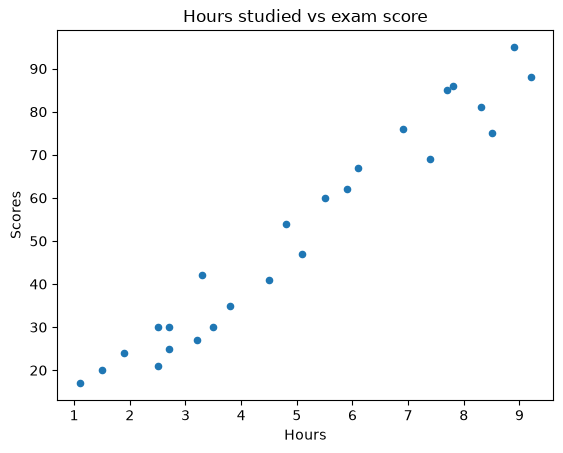

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("student_scores.csv")

print(df.describe())
print(df.corr())

df.plot.scatter(x="Hours", y="Scores", title="Hours studied vs exam score")
plt.show()

**Explanation:** describe() summarises both columns, and corr() shows a very strong positive correlation between Hours and Scores. The scatter plot shows the points lie close to a straight line, so linear regression is a good fit.

**Diagram:** Each step of the workflow, from data to evaluation.

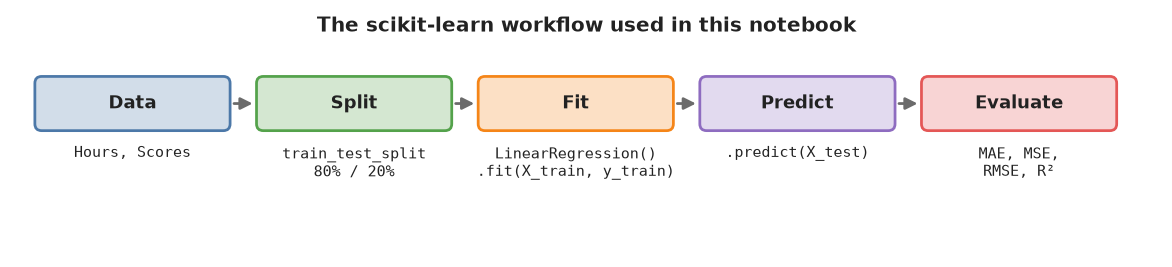

**Split the data into training and test sets**

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("student_scores.csv")

X = df["Hours"].values.reshape(-1, 1)
y = df["Scores"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])

Training rows: 20
Test rows: 5


**Explanation:** X is the feature (Hours) and y is the target (Scores). scikit-learn expects X to be 2-D, so reshape(-1, 1) turns it into one column. train_test_split() keeps 80% of the rows for training and 20% for testing. random_state makes the split repeatable.

**Diagram:** The green line is what the model learns; the red lines are the errors it minimises.

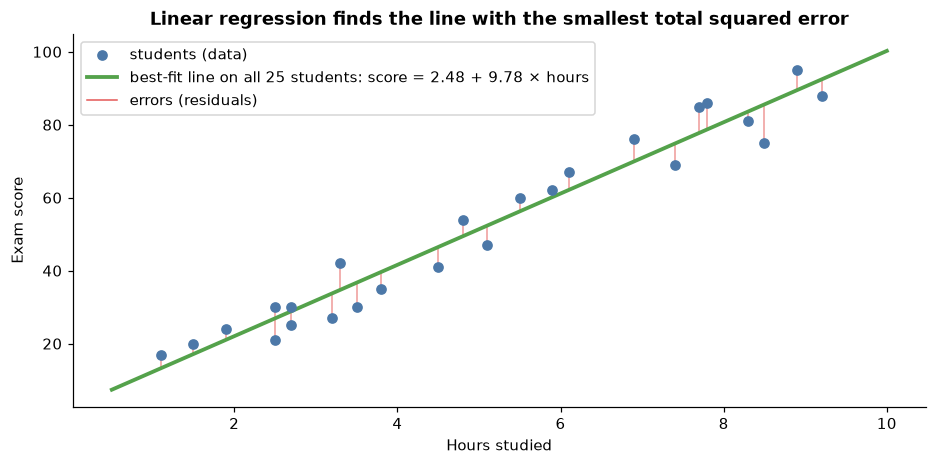

**Train the linear regression model**

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_csv("student_scores.csv")
X = df["Hours"].values.reshape(-1, 1)
y = df["Scores"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

regressor = LinearRegression()
regressor.fit(X_train, y_train)

print("Intercept:", regressor.intercept_)
print("Coefficient:", regressor.coef_)

Intercept: 2.826892353899737
Coefficient: [9.68207815]


**Explanation:** fit() finds the best straight line, score = intercept + coefficient × hours. The coefficient is how many extra marks each extra hour of study adds.

**Make predictions**

In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_csv("student_scores.csv")
X = df["Hours"].values.reshape(-1, 1)
y = df["Scores"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

regressor = LinearRegression()
regressor.fit(X_train, y_train)

print("Predicted score for 9.5 hours:", regressor.predict([[9.5]])[0])

y_pred = regressor.predict(X_test)
results = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})
print(results)

Predicted score for 9.5 hours: 94.80663482122885
   Actual  Predicted
0      81  83.188141
1      30  27.032088
2      21  27.032088
3      76  69.633232
4      62  59.951153


**Explanation:** predict() uses the fitted line to estimate scores. The table compares the actual and predicted scores for the test rows.

**Plot the regression line**

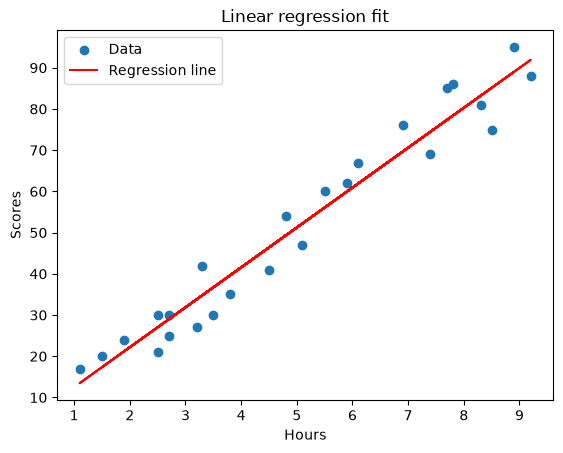

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_csv("student_scores.csv")
X = df["Hours"].values.reshape(-1, 1)
y = df["Scores"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

regressor = LinearRegression()
regressor.fit(X_train, y_train)

plt.scatter(X, y, label="Data")
plt.plot(X, regressor.predict(X), color="red", label="Regression line")
plt.xlabel("Hours")
plt.ylabel("Scores")
plt.title("Linear regression fit")
plt.legend()
plt.show()

**Explanation:** The red line is the model's prediction for every number of hours. Most points lie close to it.

**Evaluate the model**

In [7]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("student_scores.csv")
X = df["Hours"].values.reshape(-1, 1)
y = df["Scores"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

regressor = LinearRegression()
regressor.fit(X_train, y_train)
y_pred = regressor.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error: {mae:.2f}")
print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error: {rmse:.2f}")
print(f"R2 score: {r2:.2f}")

Mean Absolute Error: 3.92


Mean Squared Error: 18.94
Root Mean Squared Error: 4.35
R2 score: 0.97


**Explanation:** MAE is the average size of the errors, MSE is the average squared error, and RMSE is its square root, in the same units as the score. R2 shows how much of the variation in scores the model explains, where 1 is perfect.

## Observation

- Linear regression fits a straight line, score = intercept + coefficient × hours, through the data.
- The data is split into training and test sets so the model is checked on rows it has not seen.
- The model learned that each extra hour of study adds about 9.7 marks.
- The predictions are close to the actual scores: R² is about 0.97 and the RMSE is about 4.4 marks.
- MAE, MSE, RMSE and R² each measure the size of the errors in a different way.

## Conclusion

Linear regression with scikit-learn takes only a few lines: split, fit, predict and evaluate. Hours studied explain almost all of the variation in exam scores, so a straight line predicts them very well.